# Fine-Tuning IndoBERT + LoRA: Klasifikasi Wilayah (DKI vs NON_DKI)

**Model dasar**: `indobenchmark/indobert-lite-base-p2`  
**Teknik**: Low-Rank Adaptation (LoRA)  
**Task**: Klasifikasi WIlayah — `DKI` vs `NON_DKI`  
**Dataset**: 2000 berita (1000 DKI, 1000 NON_DKI), split 80:10:10 stratified


## 1. Instalasi Library

In [ ]:
!pip install transformers datasets peft accelerate scikit-learn pandas openpyxl evaluate gdown -q
!pip install datasets --upgrade -q
!pip install sentencepiece -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 16.8 MB/s eta 0:00:00


## 2. Import Library

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import torch
import evaluate
import gdown

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    BertTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
)
from peft import (
    LoraConfig,
    TaskType,
    get_peft_model,
    PeftModel,
)

# Cek GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Device: cuda
GPU: Tesla T4


## 3. Load & Eksplorasi Dataset

In [ ]:
url_rawdata = "https://docs.google.com/spreadsheets/d/1mJjCZF6OBRmArvXRLyz3mASn_iiKxU20/export?format=xlsx"
gdown.download(url_rawdata, "raw_data.xlsx", quiet=False, fuzzy=True)

df = pd.read_excel('raw_data.xlsx')
print('Shape:', df.shape)
print('\nKolom:', df.columns.tolist())
print('\nDistribusi label:')
print(df['WILAYAH'].value_counts())
df.head()

Downloading...
From: https://docs.google.com/spreadsheets/d/1mJjCZF6OBRmArvXRLyz3mASn_iiKxU20/export?format=xlsx
To: /content/raw_data.xlsx
2.40MB [00:00, 14.2MB/s]


Shape: (2000, 3)

Kolom: ['JUDUL', 'KONTEN', 'WILAYAH']

Distribusi label:
WILAYAH
DKI        1000
NON_DKI    1000
Name: count, dtype: int64


,JUDUL,KONTEN,WILAYAH
0,Kagetnya Rano Karno Usai Jakarta Jadi Kota Ter...,"JAKARTA, KOMPAS.com - Wakil Gubernur DKI Jakar...",DKI
1,Trubus Rahardiansyah: Jakarta Menjadi Kota Glo...,RM.id Rakyat Merdeka - DKI Jakarta menempati p...,DKI
2,Saat Wagub Sampai Terucap Wow Buntut &#039;Jak...,Perserikatan Bangsa-Bangsa (PBB) menobatkan Ja...,DKI
3,Dibeberkan PBB Jakarta Ibu Kota Terpadat Nomor...,DKI Jakarta menempati posisi pertama sebagai i...,DKI
4,"Jelang Nataru, Inflasi Jakarta Tetap Terkendali",Kepala Perwakilan Bank Indonesia DKI Jakarta I...,DKI


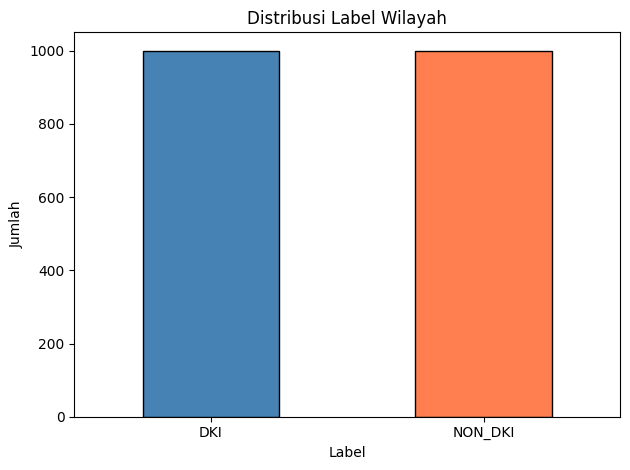

In [ ]:
# Visualisasi distribusi label
df['WILAYAH'].value_counts().plot(kind='bar', color=['steelblue', 'coral'], edgecolor='black')
plt.title('Distribusi Label Wilayah')
plt.xlabel('Label')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Preprocessing

In [ ]:
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus HTML entities
    text = re.sub(r'&#[0-9]+;', ' ', text)
    text = re.sub(r'&[a-zA-Z]+;', ' ', text)
    # Hapus tag HTML
    text = re.sub(r'<[^>]+>', ' ', text)
    # Hapus URL
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # Hapus karakter selain huruf, angka, spasi, tanda baca
    text = re.sub(r'[^\w\s.,!?;:\-\'"()]', ' ', text)
    # Normalisasi whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # Lowercase
    text = text.lower()
    return text

In [ ]:
# Gunakan KONTEN sebagai input teks
df['text'] = df['KONTEN'].apply(clean_text)

# Label encoding: DKI=1, NON_DKI=0
label2id = {'DKI': 1, 'NON_DKI': 0}
id2label = {v: k for k, v in label2id.items()}
df['label'] = df['WILAYAH'].map(label2id)

print('Contoh teks setelah cleaning:')
print(df['text'].iloc[0][:300])
print('\nLabel encoding:', label2id)

Contoh teks setelah cleaning:
jakarta, kompas.com - wakil gubernur dki jakarta rano karno mengaku kaget dengan laporan perserikatan bangsa-bangsa (pbb) yang menempatkan jakarta sebagai ibu kota terpadat di dunia dengan 42 juta penduduk.menurut rano, angka tersebut berbeda jauh dari data badan pusat statistik (bps) yang menyebut 

Label encoding: {'DKI': 1, 'NON_DKI': 0}


## 5. Split Dataset (80:10:10 Stratified)

In [ ]:
# Split train (80%) dan temp (20%)
df_train, df_temp = train_test_split(
    df[['text', 'label']],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

# Split temp: val (10%) dan test (10%)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=42,
    stratify=df_temp['label']
)

print(f'Train : {len(df_train)} ({df_train["label"].value_counts().to_dict()})')
print(f'Val   : {len(df_val)} ({df_val["label"].value_counts().to_dict()})')
print(f'Test  : {len(df_test)} ({df_test["label"].value_counts().to_dict()})')

Train : 1600 ({1: 800, 0: 800})
Val   : 200 ({1: 100, 0: 100})
Test  : 200 ({1: 100, 0: 100})


## 6. Tokenisasi

In [ ]:
MODEL_NAME = 'indobenchmark/indobert-lite-base-p2'
MAX_LENGTH = 512

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)
print('Tokenizer loaded:', MODEL_NAME)
print('Tipe tokenizer  :', type(tokenizer))
print('Vocab size      :', tokenizer.vocab_size)

sample_check = tokenizer('Pemerintah Provinsi DKI Jakarta mencatat kenaikan harga.')['input_ids']
tokens_check = tokenizer.convert_ids_to_tokens(sample_check)
print('Tes kalimat:', tokens_check)

Tokenizer loaded: indobenchmark/indobert-lite-base-p2
Tipe tokenizer  : <class 'transformers.models.bert.tokenization_bert.BertTokenizer'>
Vocab size      : 29999
Tes kalimat: ['[CLS]', 'pemerintah', 'provinsi', 'dki', 'jakarta', 'mencatat', 'kenaikan', 'harga', '.', '[SEP]']


In [ ]:
def tokenize_fn(examples):
    return tokenizer(
        examples['text'],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,  # Padding dinamis via DataCollator
    )

# Konversi ke HuggingFace Dataset
train_ds = Dataset.from_pandas(df_train.reset_index(drop=True))
val_ds   = Dataset.from_pandas(df_val.reset_index(drop=True))
test_ds  = Dataset.from_pandas(df_test.reset_index(drop=True))

# Tokenisasi
train_ds = train_ds.map(tokenize_fn, batched=True)
val_ds   = val_ds.map(tokenize_fn, batched=True)
test_ds  = test_ds.map(tokenize_fn, batched=True)

# Set format PyTorch
cols = ['input_ids', 'attention_mask', 'label']
train_ds.set_format(type='torch', columns=cols)
val_ds.set_format(type='torch', columns=cols)
test_ds.set_format(type='torch', columns=cols)

print('Tokenisasi selesai.')

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Tokenisasi selesai.


## 7. Konfigurasi LoRA

In [ ]:
# load base model
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 46.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] AlbertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-lite-base-p2
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
!pip uninstall torchao -y

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.7MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
# Konfigurasi LoRA
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,        # task: sequence classification
    r=16,                              # rank matriks LoRA
    lora_alpha=32,                     # scaling factor (alpha/r = 2)
    target_modules=['query', 'value'], # target layer attention IndoBERT
    lora_dropout=0.1,                  # dropout untuk regularisasi
    bias='none',                       # tidak melatih bias
    inference_mode=False,
    modules_to_save=['classifier'],    # layer klasifikasi
)

# terapkan LoRA ke model
model = get_peft_model(base_model, lora_config)

# ringkasan parameter
model.print_trainable_parameters()

trainable params: 50,690 || all params: 11,735,812 || trainable%: 0.4319


## 8. Training

In [ ]:
# metrik evaluasi
accuracy_metric = evaluate.load('accuracy')
f1_metric = evaluate.load('f1')

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_metric.compute(predictions=preds, references=labels)['accuracy']
    f1  = f1_metric.compute(predictions=preds, references=labels, average='macro')['f1']
    return {'accuracy': acc, 'f1_macro': f1}

In [ ]:
training_args = TrainingArguments(
    output_dir="/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTlite_Wilayah",

    num_train_epochs=25,              # epoch
    per_device_train_batch_size=16,   # 16 berita/batch saat train
    per_device_eval_batch_size=16,    # 16 berita/batch saat eval
    learning_rate=1e-5,               # learning rate
    max_grad_norm=10,                 # clipping gradient

    eval_strategy='epoch',
    save_strategy='epoch',
    logging_strategy='epoch',
    load_best_model_at_end=True,      # pilih yang terbaik
    metric_for_best_model='f1_macro',
    greater_is_better=True,

    fp16=torch.cuda.is_available(),  # Mixed precision jika pakai GPU

    seed=42,
    report_to='none',
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer) # padding panjang token

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,   # tokenizer IndoBERT
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=12)], # in 12 epochs
)

print('Trainer siap. Memulai training...')

Trainer siap. Memulai training...


In [ ]:
train_result = trainer.train()
print('\nHasil Training:')
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.670470,0.657275,0.660000,0.659966
2,0.657271,0.643855,0.730000,0.727795
3,0.638636,0.623682,0.725000,0.724993
4,0.610809,0.592059,0.780000,0.778583
5,0.568894,0.543777,0.800000,0.799679
6,0.513249,0.482180,0.830000,0.829728
7,0.445080,0.417383,0.870000,0.870000
8,0.374688,0.350874,0.890000,0.889989
9,0.310706,0.291768,0.935000,0.934959
10,0.254404,0.242251,0.945000,0.944966



Hasil Training:
{'train_runtime': 891.7189, 'train_samples_per_second': 44.857, 'train_steps_per_second': 2.804, 'total_flos': 979471609036800.0, 'train_loss': 0.2650561086654663, 'epoch': 25.0}


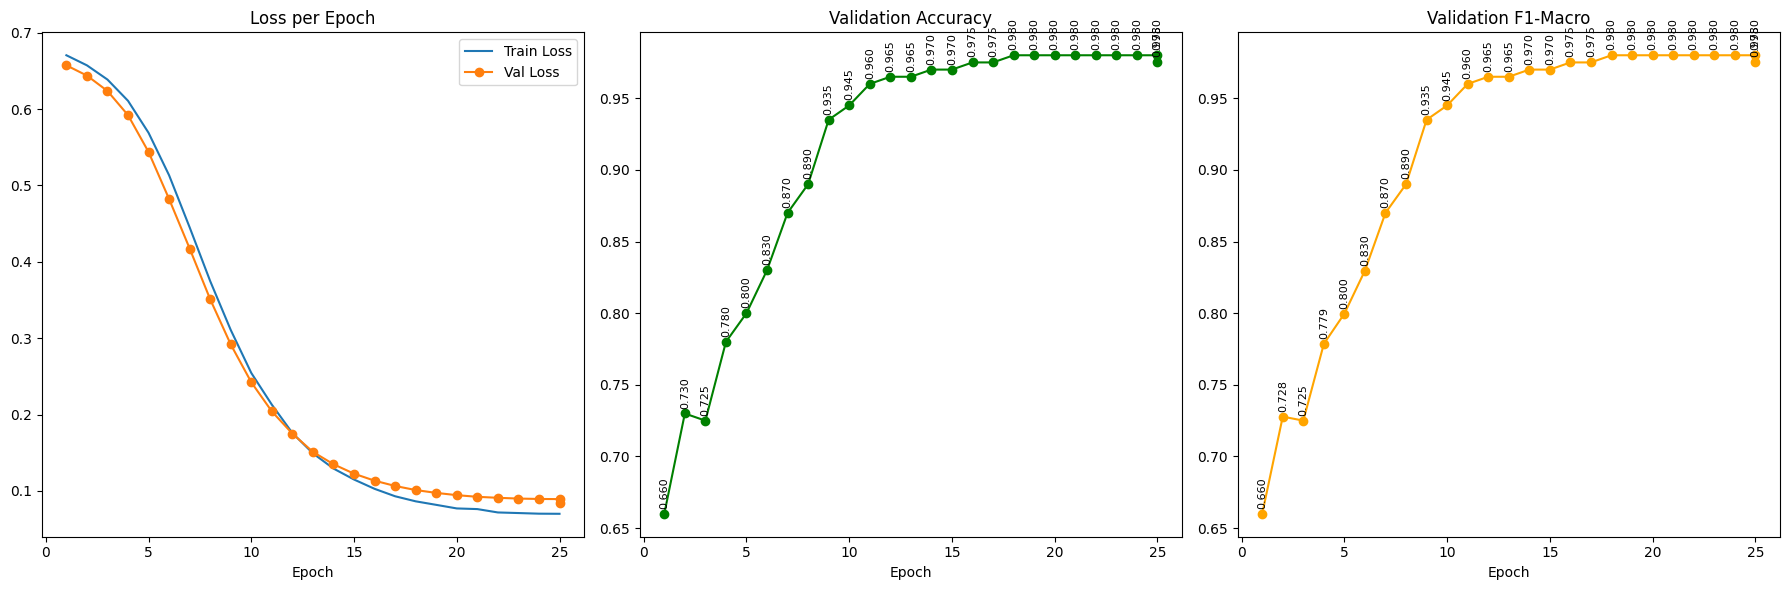

In [ ]:
# Plot training & validation loss
log_history = trainer.state.log_history

train_loss = [(x['epoch'], x['loss']) for x in log_history if 'loss' in x and 'eval_loss' not in x]
val_metrics = [(x['epoch'], x['eval_loss'], x['eval_accuracy'], x['eval_f1_macro'])
               for x in log_history if 'eval_loss' in x]

epochs_val   = [x[0] for x in val_metrics]
val_loss     = [x[1] for x in val_metrics]
val_accuracy = [x[2] for x in val_metrics]
val_f1       = [x[3] for x in val_metrics]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot Loss per Epoch
axes[0].plot([x[0] for x in train_loss], [x[1] for x in train_loss], label='Train Loss')
axes[0].plot(epochs_val, val_loss, label='Val Loss', marker='o')
axes[0].set_title('Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].legend()

# Plot Accuracy per Epoch
axes[1].plot(epochs_val, val_accuracy, color='green', marker='o')
axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
for i, txt in enumerate(val_accuracy):
    axes[1].annotate(f'{txt:.3f}', (epochs_val[i], val_accuracy[i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=8, rotation=90)

# Plot F1-macro per Epoch
axes[2].plot(epochs_val, val_f1, color='orange', marker='o')
axes[2].set_title('Validation F1-Macro')
axes[2].set_xlabel('Epoch')
for i, txt in enumerate(val_f1):
    axes[2].annotate(f'{txt:.3f}', (epochs_val[i], val_f1[i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=8, rotation=90)

plt.tight_layout()
plt.savefig('training_curve_wilayah.png', dpi=150)
plt.show()

## 9. Evaluasi pada Test Set

In [ ]:
# Evaluasi test set
test_results = trainer.evaluate(test_ds)
print('Test Set Results:')
for k, v in test_results.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.070038,0.084036,25,0.975000,0.974999


Test Set Results:
  eval_loss: 0.0840
  eval_accuracy: 0.9750
  eval_f1_macro: 0.9750


In [ ]:
predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=-1)
true_labels = predictions.label_ids

# Classification report
target_names = [id2label[i] for i in range(len(id2label))]
print('Classification Report:')
print(classification_report(true_labels, preds, target_names=target_names))

Classification Report:
              precision    recall  f1-score   support

     NON_DKI       0.97      0.98      0.98       100
         DKI       0.98      0.97      0.97       100

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200



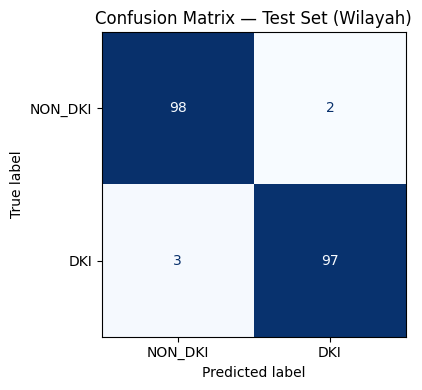

In [ ]:
# Confusion Matrix
cm = confusion_matrix(true_labels, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix — Test Set (Wilayah)')
plt.tight_layout()
plt.savefig('confusion_matrix_wilayah.png', dpi=150)
plt.show()

In [ ]:
import numpy as np

predictions = trainer.predict(test_ds)

logits = predictions.predictions[0] if isinstance(predictions.predictions, tuple) else predictions.predictions
pred_labels = np.argmax(logits, axis=-1)
true_labels = predictions.label_ids

# map label
id2label = {0: "NON_DKI", 1: "DKI"}

unique_classes = np.unique(true_labels)

print("\n=== DEBUG TEBAKAN MODEL ===")

for c in unique_classes:
    indices = np.where(true_labels == c)[0]
    true_label_name = id2label.get(c, f"Kelas {c}")

    print(f"\nKATEGORI ASLI: {true_label_name.upper()}")
    print("="*70)

    for i, idx in enumerate(indices[:3]):
        # input_ids
        raw_input_ids = test_ds[int(idx)]['input_ids']

        if hasattr(raw_input_ids, "tolist"):
            token_list = raw_input_ids.tolist()
        else:
            token_list = raw_input_ids

        if isinstance(token_list, list) and len(token_list) > 0 and isinstance(token_list[0], list):
            token_list = token_list[0]

        # bandingkan teks
        text_clean = tokenizer.decode(token_list, skip_special_tokens=True)
        text_raw = tokenizer.decode(token_list, skip_special_tokens=False)

        pred_label_name = id2label.get(pred_labels[idx], f"Kelas {pred_labels[idx]}")
        status = "✅ BENAR" if c == pred_labels[idx] else "❌ SALAH"

        print(f"[{i+1}] Tebakan Model: {pred_label_name} {status}")
        print(f"Teks (Clean) : '{text_clean[:250]}'")
        print(f"Teks (Raw)   : '{text_raw[:250]}'")
        print("-" * 70)


=== DEBUG TEBAKAN MODEL ===

KATEGORI ASLI: NON_DKI
[1] Tebakan Model: NON_DKI ✅ BENAR
Teks (Clean) : 'aksara jabar menteri perhubungan dudy purwagandhi mengungkapkan bahwa sekitar 119, 5 juta warga indonesia diperkirakan akan melakukan perjalanan, baik antarprovinsi maupun dalam provinsi, selama libur natal 2025 dan tahun baru 2026. menurut dudy, sur'
Teks (Raw)   : '[CLS] aksara jabar menteri perhubungan dudy purwagandhi mengungkapkan bahwa sekitar 119, 5 juta warga indonesia diperkirakan akan melakukan perjalanan, baik antarprovinsi maupun dalam provinsi, selama libur natal 2025 dan tahun baru 2026. menurut dud'
----------------------------------------------------------------------
[2] Tebakan Model: NON_DKI ✅ BENAR
Teks (Clean) : 'krjogja. com - yogya kenaikan harga sejumlah komoditas pangan kembali memberi tekanan pada laju inflasi di daerah istimewa yogyakarta ( diy ) sepanjang november 2025. badan pusat statistik ( bps ) diy mencatat inflasi tahunan mencapai 2, 92 persen, d'
Te

## 10. Simpan Model

In [ ]:
SAVE_DIR        = './indobertlite-lora-wilayah-final'
MERGED_SAVE_DIR = './indobertlite-wilayah-merged'

# Simpan LoRA adapter weights
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
print(f'LoRA adapter tersimpan di: {SAVE_DIR}')

# Merge LoRA weights ke base model
merged_model = model.merge_and_unload()
merged_model.save_pretrained(MERGED_SAVE_DIR)
tokenizer.save_pretrained(MERGED_SAVE_DIR)
print(f'Merged model tersimpan di: {MERGED_SAVE_DIR}')

# Simpan ke Google Drive
from google.colab import drive
import shutil, os

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

for current_dir_to_save in [SAVE_DIR, MERGED_SAVE_DIR]:
    drive_dest_folder_name = os.path.basename(current_dir_to_save)
    dest = f'/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTlite_Wilayah/{drive_dest_folder_name}'

    os.makedirs(os.path.dirname(dest), exist_ok=True)

    if os.path.exists(dest):
        shutil.rmtree(dest)

    shutil.copytree(current_dir_to_save, dest)
    print(f'✓ Tersimpan di Google Drive: {dest}')

LoRA adapter tersimpan di: ./indobertlite-lora-wilayah-final


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Merged model tersimpan di: ./indobertlite-wilayah-merged
✓ Tersimpan di Google Drive: /content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTlite_Wilayah/indobertlite-lora-wilayah-final
✓ Tersimpan di Google Drive: /content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTlite_Wilayah/indobertlite-wilayah-merged


## 11. Inference (Uji Coba Prediksi)

In [ ]:
def predict_wilayah(text, model, tokenizer, device):
    """Prediksi label wilayah satu teks berita."""
    model.eval()
    clean = clean_text(text)
    inputs = tokenizer(
        clean,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors='pt',
        padding=True,
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    probs  = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()
    pred   = int(np.argmax(probs))

    return {
        'label': id2label[pred],
        'confidence': float(probs[pred]),
        'probs': {id2label[i]: float(probs[i]) for i in range(len(probs))}
    }

model.to(device)

contoh_dki = "Inflasi Jakarta pada bulan Januari 2025 tercatat sebesar 0,3 persen. \
    BPS DKI Jakarta mencatat kenaikan harga terjadi pada kelompok makanan."

contoh_non_dki = "Pemerintah Provinsi Bali mencatat jumlah wisatawan mancanegara \
    meningkat 15 persen pada kuartal pertama tahun 2025."

print('=== Contoh Prediksi ===')
print('\n[Teks 1 - Seharusnya DKI]')
print(contoh_dki)
hasil1 = predict_wilayah(contoh_dki, model, tokenizer, device)
print(f'Prediksi: {hasil1["label"]} (confidence: {hasil1["confidence"]:.4f})')
print(f'Probabilitas: {hasil1["probs"]}')

print('\n[Teks 2 - Seharusnya NON_DKI]')
print(contoh_non_dki)
hasil2 = predict_wilayah(contoh_non_dki, model, tokenizer, device)
print(f'Prediksi: {hasil2["label"]} (confidence: {hasil2["confidence"]:.4f})')
print(f'Probabilitas: {hasil2["probs"]}')

=== Contoh Prediksi ===

[Teks 1 - Seharusnya DKI]
Inflasi Jakarta pada bulan Januari 2025 tercatat sebesar 0,3 persen.     BPS DKI Jakarta mencatat kenaikan harga terjadi pada kelompok makanan.
Prediksi: DKI (confidence: 0.8221)
Probabilitas: {'NON_DKI': 0.17788226902484894, 'DKI': 0.8221176862716675}

[Teks 2 - Seharusnya NON_DKI]
Pemerintah Provinsi Bali mencatat jumlah wisatawan mancanegara     meningkat 15 persen pada kuartal pertama tahun 2025.
Prediksi: DKI (confidence: 0.7607)
Probabilitas: {'NON_DKI': 0.23929379880428314, 'DKI': 0.7607062458992004}


## 12. Load Model yang Tersimpan

In [ ]:
# Load merge model
from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR  = '/content/drive/MyDrive/Skripsi/Fine-tuning/IndoBERTlite_Wilayah/indobertlite-wilayah-merged'
MAX_LENGTH = 512

from transformers import AutoModelForSequenceClassification, AutoTokenizer
tokenizer_loaded = AutoTokenizer.from_pretrained(DRIVE_DIR, local_files_only=True)
model_loaded = AutoModelForSequenceClassification.from_pretrained(
    DRIVE_DIR, local_files_only=True
)
model_loaded.to(device)
model_loaded.eval()
print(f'Model berhasil dimuat dan dipindah ke: {device}')

# Load LoRA adapter
# from peft import PeftModel
# from transformers import AutoModelForSequenceClassification, AutoTokenizer
#
# tokenizer_loaded = AutoTokenizer.from_pretrained('./indobert-lora-wilayah-final')
# base = AutoModelForSequenceClassification.from_pretrained(
#     'indolem/indobert-base-uncased', num_labels=2,
# #     id2label=id2label, label2id=label2id
# )
# model_loaded = PeftModel.from_pretrained(base, './indobert-lora-wilayah-final')
# model_loaded.eval()

Mounted at /content/drive


Loading weights:   0%|          | 0/27 [00:00<?, ?it/s]

Model berhasil dimuat dan dipindah ke: cuda


In [ ]:
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus HTML entities
    text = re.sub(r'&#[0-9]+;', ' ', text)
    text = re.sub(r'&[a-zA-Z]+;', ' ', text)
    # Hapus tag HTML
    text = re.sub(r'<[^>]+>', ' ', text)
    # Hapus URL
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # Hapus karakter selain huruf, angka, spasi, tanda baca
    text = re.sub(r'[^\w\s.,!?;:\-\'"()]', ' ', text)
    # Normalisasi whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # Lowercase
    text = text.lower()
    return text

def predict_wilayah(text, model, tokenizer, device):
    """Prediksi label wilayah satu teks berita."""
    model.eval()
    clean = clean_text(text)
    inputs = tokenizer(
        clean,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors='pt',
        padding=True,
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    probs  = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()
    pred   = int(np.argmax(probs))

    return {
        'label': id2label[pred],
        'confidence': float(probs[pred]),
        'probs': {id2label[i]: float(probs[i]) for i in range(len(probs))}
    }

In [ ]:
berita = """Gubernur DKI Jakarta, Pramono Anung, menyatakan bahwa partisipasi masyarakat dalam Pendataan Lapangan Sensus Ekonomi 2026 (SE2026) yang dilakukan Badan Pusat Statistik (BPS) penting untuk menghasilkan data ekonomi Jakarta yang akurat, sebagai dasar pemerintah dalam menyusun kebijakan.
Gubernur sendiri menerima menerima petugas BPS DKI Jakarta yang melakukan pendataan Sensus Ekonomi 2026, baru-baru ini.
"Petugas BPS yang datang hari ini secara langsung menanyakan sesuai dengan tugas dalam melakukan sensus. Saya menjawab secara apa adanya, sesuai kondisi sebenarnya," kata Pramono.
Ia kemudian mendorong masyarakat yang belum terdata maupun yang masih ragu memberikan informasi agar terbuka kepada petugas BPS. Menurutnya, data yang akurat membantu pemerintah memahami kondisi perekonomian Jakarta secara lebih utuh.
"Saya mengimbau kepada masyarakat di Jakarta untuk membantu BPS dalam melakukan tugas mereka, yaitu sensus ekonomi. Saya mengimbau seluruh masyarakat Jakarta untuk memberikan data apa adanya. Jangan tertutup," ujarnya.
Pramono menegaskan, informasi yang diberikan dalam Sensus Ekonomi 2026 bersifat rahasia. Pendataan dipastikan tidak berkaitan dengan perpajakan ataupun kepentingan lain di luar kebutuhan statistik.
"Ini betul-betul adalah sensus ekonomi untuk mengetahui potret kondisi dan keadaan di Jakarta. Masyarakat diminta memberikan jawaban apa adanya, sesuai dengan kondisi yang sebenarnya, karena data ini akan menjadi referensi dalam mengambil keputusan," tutur Pramono.
Sebagai salah satu pusat kegiatan ekonomi terbesar di Indonesia, keberagaman kegiatan usaha yang tumbuh di Jakarta, mulai dari usaha rumahan, UMKM, hingga perusahaan berskala besar dan internasional, perlu tercatat agar gambaran perekonomian Jakarta tidak hanya mencerminkan kegiatan usaha yang terlihat secara kasatmata.
Selama pendataan, petugas BPS mendatangi berbagai lokasi usaha, seperti mal, kawasan bisnis, pasar, pertokoan, pusat perbelanjaan, rumah, dan apartemen untuk bertemu langsung dengan pelaku usaha dan masyarakat.
Sementara, sebagian responden mengikuti pendataan melalui pengisian kuesioner secara mandiri.
Sensus Ekonomi ini bukan hanya menghitung jumlah usaha. Data yang dikumpulkan mencakup jenis kegiatan usaha, produk dan jasa yang dihasilkan, skala usaha, tenaga kerja, pemanfaatan teknologi, serta berbagai karakteristik lainnya.
Data itu diharapkan memberikan gambaran yang lebih lengkap mengenai perkembangan ekonomi Jakarta, termasuk usaha yang selama ini belum tercatat dalam data administrasi pemerintah.
Untuk diketahui, hasil SE2026 akan menjadi salah satu rujukan Pemerintah Provinsi (Pemprov) DKI Jakarta dalam menyusun program, kebijakan, regulasi, dan intervensi yang lebih tepat sasaran berdasarkan kondisi ekonomi terkini.
"Data yang benar akan membantu pemerintah mengambil keputusan yang benar. Karena itu saya mengajak masyarakat untuk ikut menyukseskan sensus ekonomi," ujar Gubernur.
Dalam kesempatan yang sama, ia juga meminta Dinas Pendidikan DKI Jakarta melakukan pengecekan ulang terhadap mahasiswa penerima Kartu Jakarta Mahasiswa Unggul (KJMU) yang terdampak perubahan data desil.
Langkah ini bertujuan memastikan mahasiswa yang sebelumnya menerima KJMU tidak kehilangan akses pendidikan akibat perubahan data yang masih perlu diverifikasi.
Sementara itu, Sekretaris Utama BPS RI, Zulkipli, mengatakan pelaksanaan pendataan Sensus Ekonomi 2026 di Jakarta berjalan lancar.
Berdasarkan pre-list yang tersedia, BPS telah melakukan pendataan sebesar 111 persen. Hingga kini, masih terdapat sejumlah unit usaha yang belum ditemukan atau dokumennya masih dalam proses penelusuran.
"Waktu kita masih ada sampai dengan 15 September. Kami akan mendatangi kembali perusahaan-perusahaan itu serta menemukan kembali yang tadinya belum ditemukan dalam pre-list kami," kata Zulikpli.
Zulkipli juga mengajak masyarakat dan pelaku usaha yang belum terdata untuk menghubungi Kantor BPS. Pendataan masih akan berlangsung hingga pertengahan September 2026.
"Untuk masyarakat di DKI Jakarta dapat membantu BPS dalam pelaksanaan Sensus Ekonomi 2026. Bagi yang belum terdata, nanti kita bisa lakukan pendataan atau bisa menghubungi kantor BPS. Waktu kita masih ada hingga pertengahan September 2026," pungkas Zulkipli.
https://www.cnnindonesia.com/nasional/20260901114547-25-1398660/gubernur-dki-ikuti-sensus-ekonomi-dorong-warga-terbuka-pada-petugas"""


import time

def predict_wilayah(text, model, tokenizer, device):
    """Prediksi label wilayah satu teks berita."""
    model.eval()
    clean = clean_text(text)
    inputs = tokenizer(
        clean,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors='pt',
        padding=True,
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    logits = outputs.logits
    probs  = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()
    pred   = int(np.argmax(probs))

    return {
        'label': id2label[pred],
        'confidence': float(probs[pred]),
        'probs': {id2label[i]: float(probs[i]) for i in range(len(probs))}
    }

def timed_predict(text, model, tokenizer, device):
    """Prediksi + ukur runtime inferensi (dalam detik) untuk satu teks (single run)."""
    if device.type == 'cuda':
        torch.cuda.synchronize()  # cek GPU tidak beroperasi

    start = time.perf_counter()
    hasil = predict_wilayah(text, model, tokenizer, device)
    if device.type == 'cuda':
        torch.cuda.synchronize()  # tunggu GPU selesai sebelum stop timer
    end = time.perf_counter()
    duration_s = (end - start)

    return hasil, duration_s

# print hasil klasifikasi loaded model
hasil, durasi_s = timed_predict(berita, model_loaded, tokenizer_loaded, device)

print('=== Hasil Klasifikasi (Model Tersimpan) ===')
print(f"Prediksi   : {hasil['label']}")
print(f"Confidence : {hasil['confidence']:.4f}")
print(f"Probabilitas: {hasil['probs']}")

# print inference time
print(f"\n=== Runtime Inferensi ({device}) — satu kali percobaan ===")
print(f"Waktu Eksekusi : {durasi_s:.3f} s")

=== Hasil Klasifikasi (Model Tersimpan) ===
Prediksi   : DKI
Confidence : 0.9736
Probabilitas: {'NON_DKI': 0.026369957253336906, 'DKI': 0.9736300706863403}

=== Runtime Inferensi (cuda) — satu kali percobaan ===
Waktu Eksekusi : 0.438 s


In [ ]:
# inference_time pada test set
import numpy as np

test_texts  = df_test['text'].tolist()
test_labels = df_test['label'].tolist()

# Warm-up
for text in test_texts:
    _ = predict_wilayah(text, model_loaded, tokenizer_loaded, device)

durasi_test_s = []
pred_test     = []

for text in test_texts:
    if device.type == 'cuda':
        torch.cuda.synchronize()   # cek GPU tidak beroperasi
    start = time.perf_counter()
    hasil = predict_wilayah(text, model_loaded, tokenizer_loaded, device)
    if device.type == 'cuda':
        torch.cuda.synchronize()   # tunggu GPU selesai sebelum stop timer
    end = time.perf_counter()

    durasi_test_s.append(end - start)
    pred_test.append(id2label_inv[hasil['label']] if 'id2label_inv' in dir() else hasil['label'])

durasi_test_s = np.array(durasi_test_s)

print(f"=== Runtime Inferensi pada Test Set ({len(test_texts)} data, {device}) ===")
print(f"Rata-rata             : {durasi_test_s.mean():.3f} s")
print(f"Std. dev              : {durasi_test_s.std():.3f} s")
print(f"Median                : {np.median(durasi_test_s):.3f} s")
print(f"Min / Max             : {durasi_test_s.min():.3f} s / {durasi_test_s.max():.3f} s")
print(f"Total waktu           : {durasi_test_s.sum():.2f} s")
print(f"Throughput            : {len(test_texts)/durasi_test_s.sum():.2f} sampel/detik")

=== Runtime Inferensi pada Test Set (200 data, cuda) ===
Rata-rata             : 0.033 s
Std. dev              : 0.008 s
Median                : 0.033 s
Min / Max             : 0.013 s / 0.078 s
Total waktu           : 6.55 s
Throughput            : 30.55 sampel/detik
